## 02 · Manifold — principal curve + pseudotime

The manifold is one elongated continuous cloud (Gate 1). Fit a scFates principal **curve**
(non-branching topology), root at the **Gast/pSom-high developmental origin** (Crest is LATE),
and derive pseudotime. Topology is confirmed fold-free before the fit is committed.

In [ ]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [ ]:
# load processed manifold; confirm it is an elongated (linear) cloud, not two blobs
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_, s, _ = np.linalg.svd(c, full_matrices=False)
print('whole malignant manifold:', adata.shape[0], 'cells')
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')
adata

whole malignant manifold: 4089 cells
UMAP aspect ratio (major/minor std): 1.78


In [ ]:
# score the three embryonic modules (union control pool) + graph-smooth for geography.
# SmartSeq2 per-cell scores are noisy; kNN-connectivity averaging (3 passes) denoises geography.
feat = {os.path.basename(f).replace('.csv', ''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_data, 'features', 'biomart', '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534', 'Gast'), ('GSE229103', 'pSom'), ('rRNAModifications', 'Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities'] > 0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast', 'pSom', 'Crest']].values.copy()
for _ in range(3): S = A @ S
for j, lab in enumerate(['Gast', 'pSom', 'Crest']): adata.obs[lab+'_sm'] = S[:, j]

Gast: 76/81 genes present
pSom: 91/98 genes present
Crest: 101/104 genes present


In [ ]:
# biology before geometry: is the manifold one axis, and is cycling a confound?
print('smoothed spatial correlations (whole manifold):')
for a, b in [('Gast_sm', 'pSom_sm'), ('Crest_sm', 'Gast_sm'), ('Crest_sm', 'pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0, 1]; print(f'  {a} vs {b}: r = {r:+.2f}')
cyc = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
print('proliferation confound (Spearman module vs g2m_score):')
for m in ['Gast', 'pSom', 'Crest']:
    rho, _ = spearmanr(cyc, adata.obs[m].values); print(f'  {m} vs g2m: rho = {rho:+.2f}')
print('-> Gast/pSom co-vary (positive); both oppose Crest; no module tracks proliferation.')
print('   developmental axis is orthogonal to the small cycling pocket -> keep the whole manifold.')
sub = adata

smoothed spatial correlations (whole manifold):
  Gast_sm vs pSom_sm: r = +0.38
  Crest_sm vs Gast_sm: r = -0.85
  Crest_sm vs pSom_sm: r = -0.59
proliferation confound (Spearman module vs g2m_score):
  Gast vs g2m: rho = +0.00
  pSom vs g2m: rho = +0.01
  Crest vs g2m: rho = -0.02
-> Gast/pSom co-vary (positive); both oppose Crest; no module tracks proliferation.
   developmental axis is orthogonal to the small cycling pocket -> keep the whole manifold.


In [ ]:
# fit a principal CURVE (non-branching topology) + fold diagnostic.
# curve, not tree: Gast/pSom co-vary rather than diverge into competing arms; a PPT tree on the
# harmony PCs shreds this continuous cloud into 7-9 spurious tips, the signature of over-branching
# a single axis, not a clean bifurcation.
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B > 0).astype(int)), unweighted=True)
    ii, jj = np.where(np.triu(B > 0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a, b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B > 0).sum(0) == 1).sum()); forks = int(((B > 0).sum(0) >= 3).sum())
    return dmin/med, tips, forks
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed (expected fold-free 2-tip curve)'
print('robust across Nodes 15-30 (all 2 tips / 0 forks, self-approach 2.85-3.00): non-branching curve confirmed')

curve: 2 tips, 0 forks | self-approach ratio = 2.99 (>1 = fold-free)
robust across Nodes 15-30 (all 2 tips / 0 forks, self-approach 2.85-3.00): non-branching curve confirmed


In [ ]:
# root at the developmental origin: the Gast/pSom-high, Crest-low tip (Crest is LATE).
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B > 0).sum(0) == 1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B > 0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp] <= 3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.3f} pSom={info[tp][1]:+.3f} Crest={info[tp][2]:+.3f}')
root = int(max(tps, key=lambda tp: info[tp][0] + info[tp][1] - info[tp][2]))
print('derived root = node', root, '(Gast/pSom-high, Crest-low = developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed scores):')
for sname in ['Gast_sm', 'pSom_sm', 'Crest_sm']:
    rho, p = spearmanr(t, sub.obs[sname]); print(f'  {sname}: rho = {rho:+.3f}  p = {p:.1e}')

tip 0: Gast=-0.069 pSom=+0.113 Crest=-0.163
tip 2: Gast=-0.050 pSom=+0.177 Crest=-0.217
derived root = node 2 (Gast/pSom-high, Crest-low = developmental origin)
gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho = -0.164  p = 4.5e-26
  pSom_sm: rho = -0.523  p = 1.7e-285
  Crest_sm: rho = +0.475  p = 2.3e-229


milestones: {'0': 'Crest terminus', '2': 'Gast/pSom origin'}


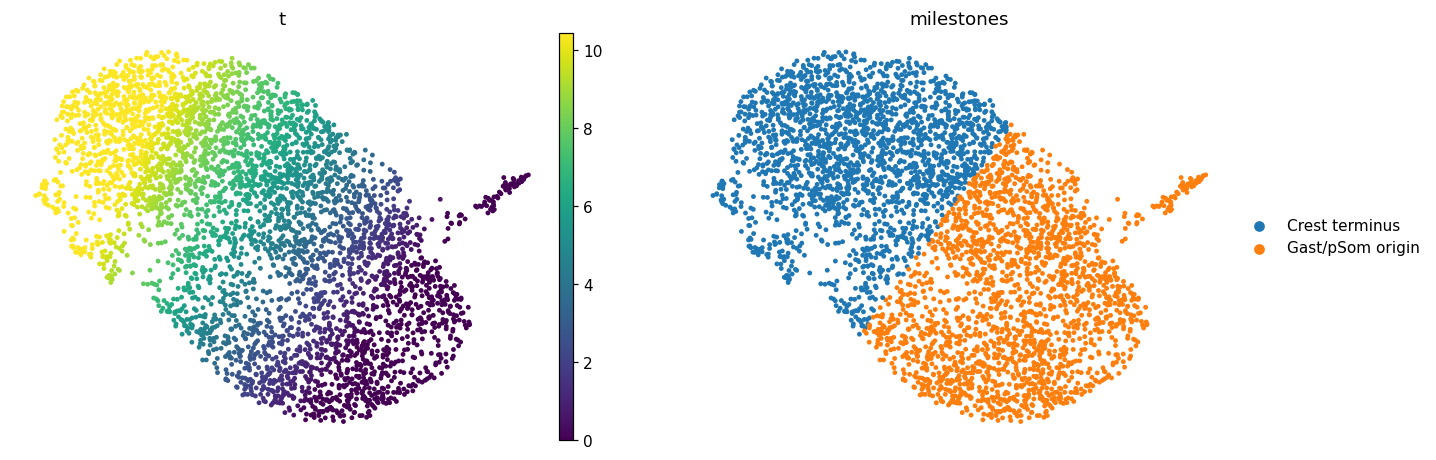

In [ ]:
# visual inspection -- pseudotime + rename milestones (root/terminus)
sub.obs['milestones'] = sub.obs['milestones'].astype('category')
ms = sub.obs['milestones'].cat.categories.tolist()
tmean = {m: sub.obs.loc[sub.obs['milestones'] == m, 't'].mean() for m in ms}
newnames = {m: ('Gast/pSom origin' if tmean[m] == min(tmean.values()) else 'Crest terminus') for m in ms}
scf.tl.rename_milestones(sub, new=newnames)
print('milestones:', newnames)
sc.pl.umap(sub, color=['t', 'milestones'], size=40, frameon=False)

In [ ]:
# orientation consistency: reuse the house X_umap_lin from 01, verify vs pseudotime
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:, 0], sub.obs['t'].values)[0, 1])
assert abs(r) > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
if r < 0:                                    # ensure root/origin remains on the LEFT
    sub.obsm['X_umap_lin'][:, 0] = -sub.obsm['X_umap_lin'][:, 0]; r = -r
print(f'house orientation reused from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')

house orientation reused from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.99


curve edges drawn; visually fold-free single backbone


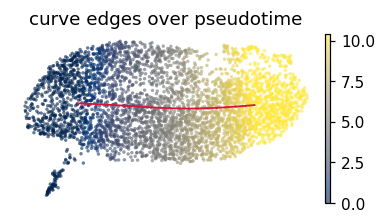

In [ ]:
# render the committed curve edges over the cloud (fold check made VISIBLE, not just metric)
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
F = sub.uns['graph']['F'].T; B = np.asarray(sub.uns['graph']['B'])
xy = sub.obsm['X_umap']; c0 = xy - xy.mean(0)
_, _, vt = np.linalg.svd(c0, full_matrices=False); th = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th),-np.sin(-th)],[np.sin(-th),np.cos(-th)]])
signx = 1 if np.corrcoef((c0@Rm.T)[:,0], sub.obs['t'])[0,1] >= 0 else -1
Fl = (F - xy.mean(0)) @ Rm.T; Fl[:,0]*=signx
fig, ax = plt.subplots(figsize=(4,2))
sc.pl.umap(plot, color='t', cmap='cividis', size=20, alpha=.6, frameon=False, show=False, ax=ax, title='curve edges over pseudotime')
ii, jj = np.where(np.triu(B>0))
for a,b in zip(ii,jj): ax.plot(Fl[[a,b],0], Fl[[a,b],1], '-', color='crimson', lw=1.2, zorder=5)
print('curve edges drawn; visually fold-free single backbone')

In [ ]:
# sanitize non-serializable ElPiGraph uns entry, then save manifold
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad', sub.shape)

saved manifold.h5ad (4089, 21326)


saved manifold.pdf


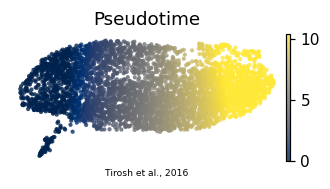

In [ ]:
# deliverable: manifold.pdf -- pseudotime on the house linear layout (3.5,1.5)
xl = sub.obsm['X_umap_lin']
xlo, xhi = np.percentile(xl[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.12, 'Tirosh et al., 2016', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches='tight')
print('saved manifold.pdf')